1. Los datos de Fashion MNIST están disponibles directamente en la API de conjuntos de datos de tf.keras. Los puedes cargar así:
mnist = tf.keras.datasets.fashion_mnist
(training_images, training_labels), (test_images, test_labels) = mnist.load_data()

In [2]:
import tensorflow as tf
from keras.src.models import model

mnist = tf.keras.datasets.fashion_mnist
(training_images, training_labels), (test_images, test_labels) = mnist.load_data()

I0000 00:00:1795544463.530581  661562 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795544463.554043  661562 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795544464.184890  661562 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [9]:
training_images.shape, training_labels.shape

((60000, 28, 28), (60000,))

In [10]:
test_images.shape, test_labels.shape

((10000, 28, 28), (10000,))

2. Visualiza el contenido de training_images[0] con un print. ¿Cuál es su forma? ¿Qué tipo de dato contiene?
Puedes visualizar una imagen en matplotlib.pyplot con el método imshow, que recibe como parámetro la imagen que quieres mostrar.

In [29]:
print(training_images[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 23

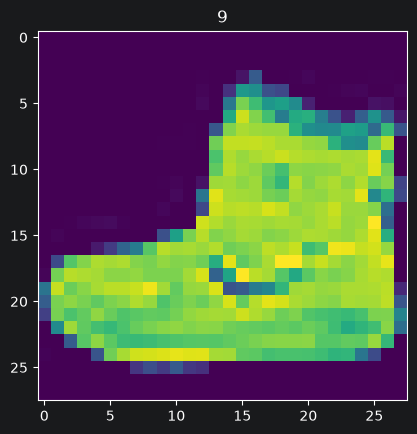

In [9]:
import matplotlib.pyplot as plt
plt.title(training_labels[0])
plt.imshow(training_images[0])

3. ¿Cuántas clases diferentes de ropa hay? Visualiza en una figura de matplotlib, 10 elementos de cada clase.

4. De las etiquetas verdaderas, crea la siguiente lista de clases:
class_names = ['Camiseta', 'Pantalón', 'Jersey', 'Vestido', 'Abrigo', 'Sandalia', 'Camisa', 'Zapatilla', 'Bolso', 'Bota']
x,idx = tf.unique(training_labels)
for i in x:
    print(class_names[i])

In [8]:
tf.unique(training_labels)

W0000 00:00:1795447251.671205    8042 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1795447251.965983    7533 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Unique(y=<tf.Tensor: shape=(10,), dtype=uint8, numpy=array([9, 0, 3, 2, 7, 5, 1, 6, 4, 8], dtype=uint8)>, idx=<tf.Tensor: shape=(60000,), dtype=int32, numpy=array([0, 1, 1, ..., 2, 1, 5], shape=(60000,), dtype=int32)>)

Camiseta
Pantalón
Jersey
Vestido
Abrigo
Sandalia
Camisa
Zapatilla
Bolso
Bota


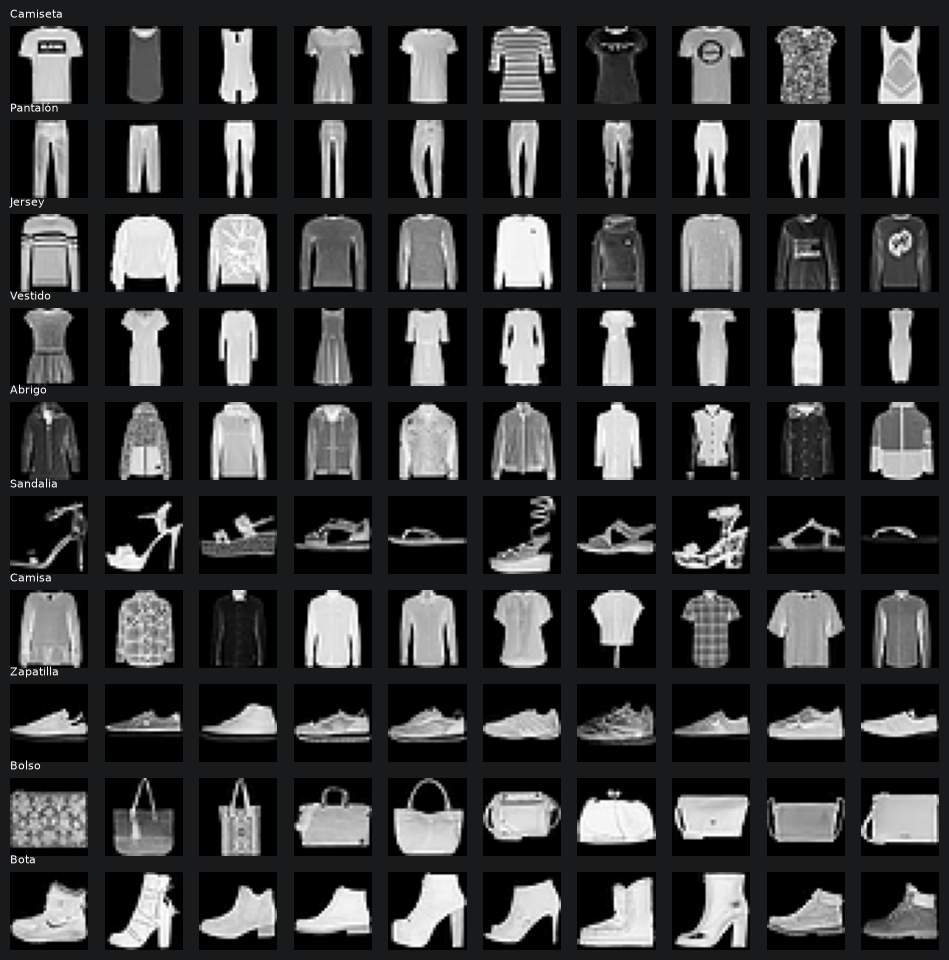

In [26]:
class_names = ['Camiseta', 'Pantalón', 'Jersey', 'Vestido', 'Abrigo', 'Sandalia', 'Camisa', 'Zapatilla', 'Bolso', 'Bota']
x,idx = tf.unique(training_labels)
fig, axes = plt.subplots(10, 10, figsize=(12, 12))
for i in range(10):
    print(class_names[i])
    for j in range(10):
        idx = (training_labels == i).nonzero()[0][j]
        axes[i, j].imshow(training_images[idx], cmap='gray')
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(class_names[i], fontsize=8, loc='left')

5. Cuando trabajamos con imágenes, para pasarlas a una RNA, es mejor escalar los valores de sus píxeles. Normalizar es simplemente convertir los valores de los píxeles a un rango 0-1 en lugar de un rango 0-255 (valores posibles de un byte). Por tanto, tan sólo tienes que dividir todos los pixeles entre 255. Puedes investigar sobre lo que es el MinMaxScaler. Escala los valores de los píxeles de todas las imágenes.

In [7]:
training_images = training_images / 255.0
test_images = test_images / 255.0

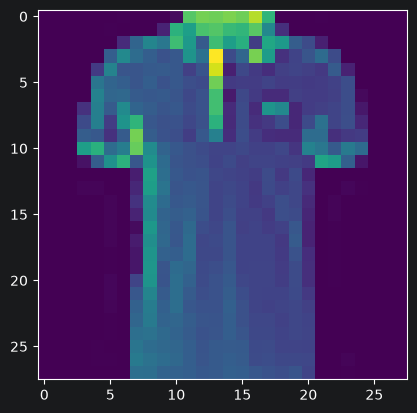

In [10]:
import random as rnd
plt.imshow(training_images[rnd.choice(range(0,len(training_images)))])

6. Crea un modelo de keras para que aprenda las diferencias entre las clases de ropa. ¿Qué forma tendrá la capa de entrada? Para que la RNA procese mejor la primera capa, hay que aplicar una capa llamada Flatten, que “aplana la matriz que representa todos los píxeles de la imagen. Por tanto, la primera capa de tu modelo será:
#define la primera capa, junto con la forma de la entrada tf.keras.layers.Flatten(input_shape=(28,28))

Introduce también en el modelo una capa oculta de 128 neuronas con la función de activación ‘relu’.
¿Cómo debe ser la capa de salida? ¿Qué función de activación debe tener?

In [44]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

7. Compila el modelo utilizando el método compile con el optimizador Adam, función de pérdida sparse_categorical_crossentropy y utilizando como métrica “Accuracy”.

In [46]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

8. Entrena el conjunto training_images durante 5 épocas. ¿Qué resultados obtienes? ¿Te parecen buenos?

In [47]:
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 751us/step - accuracy: 0.8248 - loss: 0.5009
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 701us/step - accuracy: 0.8643 - loss: 0.3792
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 699us/step - accuracy: 0.8782 - loss: 0.3403
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 698us/step - accuracy: 0.8827 - loss: 0.3175
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 699us/step - accuracy: 0.8919 - loss: 0.2944


9. Evalúa el modelo con el conjunto de test y comenta los resultados que has obtenidos

In [49]:
model.evaluate(test_images, test_labels)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 511us/step - accuracy: 0.8797 - loss: 0.3431


[0.3430969715118408, 0.8797000050544739]

10. Ejecuta el siguiente código:
classifications = model.predict(test_images)
print(classifications[0])

La salida, después de ejecutarla, es una lista de números. ¿Por qué crees que es así y qué representan esos números? ¿Qué representa esta lista? Elige la respuesta de entre las siguientes opciones
    a) Los 10 valores aleatorios menos significativos
    b) Las 10 primeras clasificaciones que hizo la RNA
    c) La probabilidad de que el elemento sea de cada una de las 10 clases

In [50]:
classifications = model.predict(test_images)
print(classifications[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 397us/step
[4.9611567e-06 4.3116266e-08 6.4927940e-07 3.8776045e-07 9.7621762e-07
 5.1205818e-02 6.3323100e-06 2.8028829e-02 4.8495331e-04 9.2026705e-01]


In [52]:
tf.argmax(classifications[0])

<tf.Tensor: shape=(), dtype=int64, numpy=9>

12. Prueba a cargar una imagen que hayas diseñado tú, escribe el código necesario para cargar la imagen y predecir su clase. Puedes utilizar la función imread del paquete cv2 (Computer Vision 2):
import cv2
mi_imagen=cv2.imread('miImagen.png',cv2.IMREAD_GRAYSCALE)
plt.imshow(mi_imagen)

NOTA: Para instalar cv2, pon pip install opencv-python

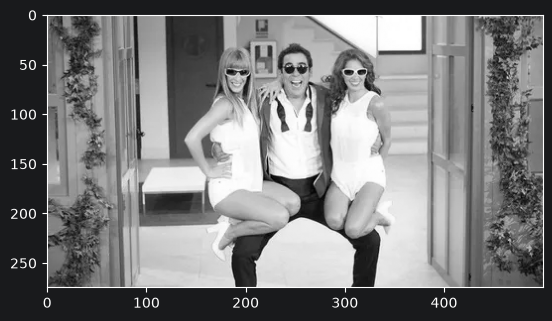

In [57]:
import cv2
mi_imagen=cv2.imread('miImagen.png',cv2.IMREAD_GRAYSCALE)
plt.imshow(mi_imagen, cmap='gray')

13. Veamos ahora las capas en tu modelo. Experimenta con diferentes valores para la capa densa con 512 neuronas. ¿Qué resultados diferentes obtienes para la pérdida, el tiempo de entrenamiento, etc.? ¿Por qué crees que es así?
Incrementa la capa oculta a 1024 neuronas -- ¿Cuál es el impacto?
    a) El entrenamiento lleva más tiempo, pero es más preciso
    b) El entrenamiento lleva más tiempo, pero no afecta la precisión
    c) El entrenamiento lleva el mismo tiempo, pero es más preciso

In [27]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [28]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [29]:
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8299 - loss: 0.4754
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8682 - loss: 0.3591
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8804 - loss: 0.3230
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8887 - loss: 0.3009
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8956 - loss: 0.2795


In [30]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(1024, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [31]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [32]:
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8310 - loss: 0.4716
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8681 - loss: 0.3585
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8834 - loss: 0.3185
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8899 - loss: 0.2966
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8973 - loss: 0.2764


14. ¿Qué pasaría si eliminas la capa Flatten()? ¿Por qué crees que es así?

In [33]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(1024, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [34]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5


ValueError: Argument `output` must have rank (ndim) `target.ndim - 1`. Received: target.shape=(32,), output.shape=(32, 28, 10)

15. Considera las capas finales (de salida). ¿Por qué hay 10? ¿Qué pasaría si tuvieras una cantidad diferente a 10? Por ejemplo, intenta entrenar la red con 5

In [35]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(5, activation='softmax')
])

In [36]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5


W0000 00:00:1795546983.644648  661705 op_kernel.cc:1858] OP_REQUIRES failed at sparse_xent_op.cc:103 : INVALID_ARGUMENT: Received a label value of 9 which is outside the valid range of [0, 5).  Label values: 0 4 9 7 5 7 3 0 4 2 5 3 5 9 1 5 0 8 5 8 8 9 9 6 4 1 9 2 2 1 0 8
W0000 00:00:1795546983.644675  661705 local_rendezvous.cc:412] Local rendezvous is aborting with status: INVALID_ARGUMENT: Received a label value of 9 which is outside the valid range of [0, 5).  Label values: 0 4 9 7 5 7 3 0 4 2 5 3 5 9 1 5 0 8 5 8 8 9 9 6 4 1 9 2 2 1 0 8
	 [[{{function_node __inference_one_step_on_data_347259}}{{node compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/SparseSoftmaxCrossEntropyWithLogits}}]]


InvalidArgumentError: Graph execution error:

Detected at node compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/SparseSoftmaxCrossEntropyWithLogits defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/home/iabd/miniconda3/envs/rna/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>

  File "/home/iabd/miniconda3/envs/rna/lib/python3.11/site-packages/traitlets/config/application.py", line 1082, in launch_instance

  File "/home/iabd/miniconda3/envs/rna/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 807, in start

  File "/home/iabd/miniconda3/envs/rna/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 211, in start

  File "/home/iabd/miniconda3/envs/rna/lib/python3.11/asyncio/base_events.py", line 608, in run_forever

  File "/home/iabd/miniconda3/envs/rna/lib/python3.11/asyncio/base_events.py", line 1936, in _

16. Considera los efectos de capas adicionales en la red. ¿Qué pasará si agregas otra capa entre la que tiene 128 y la capa final con 10?

In [37]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [38]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(training_images, training_labels, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 724us/step - accuracy: 0.2456 - loss: 1.8128
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 713us/step - accuracy: 0.3260 - loss: 1.6037
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 752us/step - accuracy: 0.3711 - loss: 1.5320
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 703us/step - accuracy: 0.3892 - loss: 1.4882
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 758us/step - accuracy: 0.4074 - loss: 1.4565


17. ¿Cuál es el impacto de poner más o menos épocas en el entrenamiento? ¿Por qué crees que sería así?

18. Prueba con 15 épocas: probablemente obtendrás un modelo con una pérdida mucho menor que el que tiene 5.

In [39]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(training_images, training_labels, epochs=15)
model.evaluate(test_images, test_labels)

Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 731us/step - accuracy: 0.8258 - loss: 0.4995
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 691us/step - accuracy: 0.8610 - loss: 0.3810
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 691us/step - accuracy: 0.8761 - loss: 0.3400
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 694us/step - accuracy: 0.8841 - loss: 0.3146
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 710us/step - accuracy: 0.8901 - loss: 0.2975
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 703us/step - accuracy: 0.8953 - loss: 0.2811
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 726us/step - accuracy: 0.8981 - loss: 0.2698
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 732us/step - accuracy: 0.9028 - loss: 0.2599
Epoch 9/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 707us/step - accuracy: 0.9081 - loss: 0.2469
Epoch 10/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 691us/step - accuracy: 0.9098 - loss: 0.2396
Epoch 11/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 726us/step - accuracy: 0.9123 - loss: 0.2308
Epoch 12

[0.35411307215690613, 0.8823000192642212]

19. Prueba 30 épocas: es posible que vea que el valor de pérdida deje de disminuir y, a veces, aumente (sobreajuste).

In [40]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(training_images, training_labels, epochs=30)
model.evaluate(test_images, test_labels)

Epoch 1/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 721us/step - accuracy: 0.8237 - loss: 0.4969
Epoch 2/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 732us/step - accuracy: 0.8641 - loss: 0.3750
Epoch 3/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 750us/step - accuracy: 0.8773 - loss: 0.3362
Epoch 4/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 717us/step - accuracy: 0.8857 - loss: 0.3123
Epoch 5/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 715us/step - accuracy: 0.8917 - loss: 0.2960
Epoch 6/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 856us/step - accuracy: 0.8964 - loss: 0.2809
Epoch 7/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 699us/step - accuracy: 0.9015 - loss: 0.2684
Epoch 8/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 717us/step - accuracy: 0.9051 - loss: 0.2566
Epoch 9/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 709us/step - accuracy: 0.9071 - loss: 0.2478
Epoch 10/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 702us/step - accuracy: 0.9107 - loss: 0.2398
Epoch 11/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 797us/step - accuracy: 0.9144 - loss: 0.2309
Epoch 12

[0.4070306420326233, 0.8866999745368958]

20. Antes de entrenar, se escalaron los datos, pasando de valores que eran 0-255 a valores que eran 0-1. ¿Cuál sería el impacto de eliminar ese proceso? ¿Por qué crees que obtienes resultados diferentes?

In [41]:
(training_images, training_labels), (test_images, test_labels) = mnist.load_data()

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(training_images, training_labels, epochs=5)
model.evaluate(test_images, test_labels)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 725us/step - accuracy: 0.6617 - loss: 2.9372 
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 818us/step - accuracy: 0.7063 - loss: 0.7764
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 722us/step - accuracy: 0.7299 - loss: 0.6749
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 722us/step - accuracy: 0.7639 - loss: 0.6248
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 831us/step - accuracy: 0.7862 - loss: 0.5876
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 536us/step - accuracy: 0.7591 - loss: 0.6737


[0.673743724822998, 0.7591000199317932]

21. Callback para que el entrenamiento se pare al llegar al 91 % de accuracy.

In [42]:
class MiCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') >= 0.91:
            print('\nSe ha llegado al 91 % de accuracy, se para el entrenamiento')
            self.model.stop_training = True

# Volver a escalar las imágenes
training_images = training_images / 255.0
test_images = test_images / 255.0

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(training_images, training_labels, epochs=30, callbacks=[MiCallback()])

Epoch 1/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 739us/step - accuracy: 0.8250 - loss: 0.4983
Epoch 2/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 703us/step - accuracy: 0.8651 - loss: 0.3753
Epoch 3/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 693us/step - accuracy: 0.8771 - loss: 0.3363
Epoch 4/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 724us/step - accuracy: 0.8859 - loss: 0.3115
Epoch 5/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 695us/step - accuracy: 0.8901 - loss: 0.2958
Epoch 6/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 683us/step - accuracy: 0.8962 - loss: 0.2792
Epoch 7/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 694us/step - accuracy: 0.9006 - loss: 0.2668
Epoch 8/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 685us/step - accuracy: 0.9050 - loss: 0.2553
Epoch 9/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 692us/step - accuracy: 0.9090 - loss: 0.2459
Epoch 10/30
1824/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 690us/step - accuracy: 0.9111 - loss: 0.2366
Se ha llegado al 91 % de accuracy, se para el entrenamiento
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 694us